<a href="https://colab.research.google.com/github/juanronaldo3012-wq/Codigo-AF-3/blob/main/PIA_MySdeSM_2226718.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Simulacion de un robot manipulador planar de 2 GDL


Simulación de 10 s

$$M(q)\ddot q+C(q,\dot q)\dot q+g(q)+f(\dot q)=\tau$$

con un controlador PD y compensacion de gravedad:

$$\tau=K_p(q_d-q)-K_v\dot q+g(q).$$

Referencias: $q_{1d}=90^\circ$ y $q_{2d}=45^\circ$.


## 1. Parametros

Los parametros se tomaron del desarrollo teorico proporcionado: longitudes,
centros de masa, masas, inercias y coeficientes de friccion en unidades SI.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp


# ---------------------------------------------------------------------------
# 1. Parametros fisicos (SI)
# ---------------------------------------------------------------------------
l1 = 0.45
l2 = 0.45
lc1 = 0.092
lc2 = 0.048
m1 = 23.902
m2 = 3.88
I1 = 1.266
I2 = 0.093
gravity = 9.81

# Friccion viscosa y de Coulomb
fv1 = 2.288
fv2 = 0.175
fc1 = 7.17


# ---------------------------------------------------------------------------


## 2. Matrices del modelo dinamico


In [ ]:
# 2. Modelo M(q) qdd + C(q, qd) qd + g(q) + f(qd) = tau
# ---------------------------------------------------------------------------
def inertia_matrix(q):
    """Matriz de inercia M(q)."""
    q1, q2 = q
    m11 = (
        I1
        + I2
        + m1 * lc1**2
        + m2 * (l1**2 + lc2**2 + 2.0 * l1 * lc2 * np.cos(q2))
    )
    m12 = I2 + m2 * (lc2**2 + l1 * lc2 * np.cos(q2))
    m22 = I2 + m2 * lc2**2
    return np.array([[m11, m12], [m12, m22]])


def coriolis_matrix(q, dq):
    """Matriz de Coriolis/centrifuga C(q, qd)."""
    _q1, q2 = q
    dq1, dq2 = dq
    h = m2 * l1 * lc2 * np.sin(q2)
    return np.array(
        [
            [-h * dq2, -h * (dq1 + dq2)],
            [h * dq1, 0.0],
        ]
    )


def gravity_vector(q):
    """Vector de pares gravitacionales g(q)."""
    q1, q2 = q
    g1 = (m1 * lc1 + m2 * l1) * gravity * np.cos(q1)
    g1 += m2 * lc2 * gravity * np.cos(q1 + q2)
    g2 = m2 * lc2 * gravity * np.cos(q1 + q2)
    return np.array([g1, g2])


def friction_vector(dq):
    """Friccion viscosa y Coulomb suavizada con tanh."""
    dq1, dq2 = dq
    return np.array(
        [fv1 * dq1 + fc1 * np.tanh(100.0 * dq1), fv2 * dq2]
    )


# ---------------------------------------------------------------------------


## 3. Controlador y ecuaciones de estado


In [ ]:
# 3. Control PD con compensacion de gravedad
# ---------------------------------------------------------------------------
q_ref = np.deg2rad(np.array([90.0, 45.0]))
Kp = np.diag([200.0, 50.0])
Kv = np.diag([60.0, 25.0])


def control_torque(q, dq):
    """tau = Kp(q_ref-q) - Kv qd + g(q)."""
    return Kp @ (q_ref - q) - Kv @ dq + gravity_vector(q)


def state_equations(t, state):
    """Ecuaciones de estado: x=[q1,q2,dq1,dq2]."""
    q = state[:2]
    dq = state[2:]

    M = inertia_matrix(q)
    C = coriolis_matrix(q, dq)
    G = gravity_vector(q)
    F = friction_vector(dq)
    tau = control_torque(q, dq)

    ddq = np.linalg.solve(M, tau - C @ dq - G - F)
    return np.concatenate((dq, ddq))


# ---------------------------------------------------------------------------


## 4. Integracion numerica de 0 a 10 segundos


In [ ]:
# 4. Simulacion de 0 a 10 s
# ---------------------------------------------------------------------------
t_eval = np.linspace(0.0, 10.0, 2001)
x0 = np.zeros(4)  # q1=q2=dq1=dq2=0

solution = solve_ivp(
    state_equations,
    (t_eval[0], t_eval[-1]),
    x0,
    t_eval=t_eval,
    # Radau es apropiado porque tanh(100*dq1) vuelve rigido al modelo
    # alrededor de velocidad cero.
    method="Radau",
    rtol=1e-7,
    atol=1e-9,
)

if not solution.success:
    raise RuntimeError(solution.message)

t = solution.t
q1, q2, dq1, dq2 = solution.y


# Cinematica directa del efector final
x_ee = l1 * np.cos(q1) + l2 * np.cos(q1 + q2)
y_ee = l1 * np.sin(q1) + l2 * np.sin(q1 + q2)


# ---------------------------------------------------------------------------


## 5. Resultados

Se muestran las posiciones articulares, la trayectoria cartesiana del efector
final, las velocidades y los pares de control. La tabla permite revisar los
valores en 1, 2, 5 y 10 s.


Resultados de la simulacion
 t [s] | q1 [rad] | q2 [rad] | q1 [deg] | q2 [deg]
----------------------------------------------------------
   1.0 |   1.4933 |   0.6821 |   85.558 |   39.082
   2.0 |   1.5370 |   0.7717 |   88.064 |   44.214
   5.0 |   1.5568 |   0.7854 |   89.196 |   44.998
  10.0 |   1.5670 |   0.7854 |   89.782 |   45.000


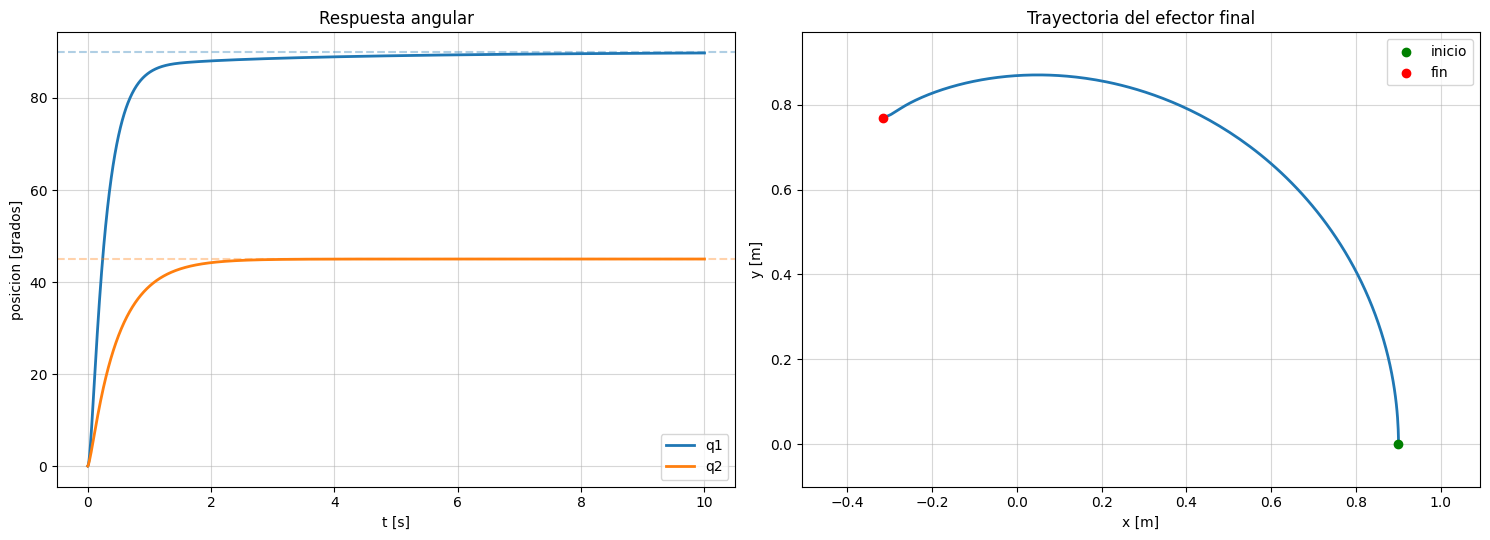

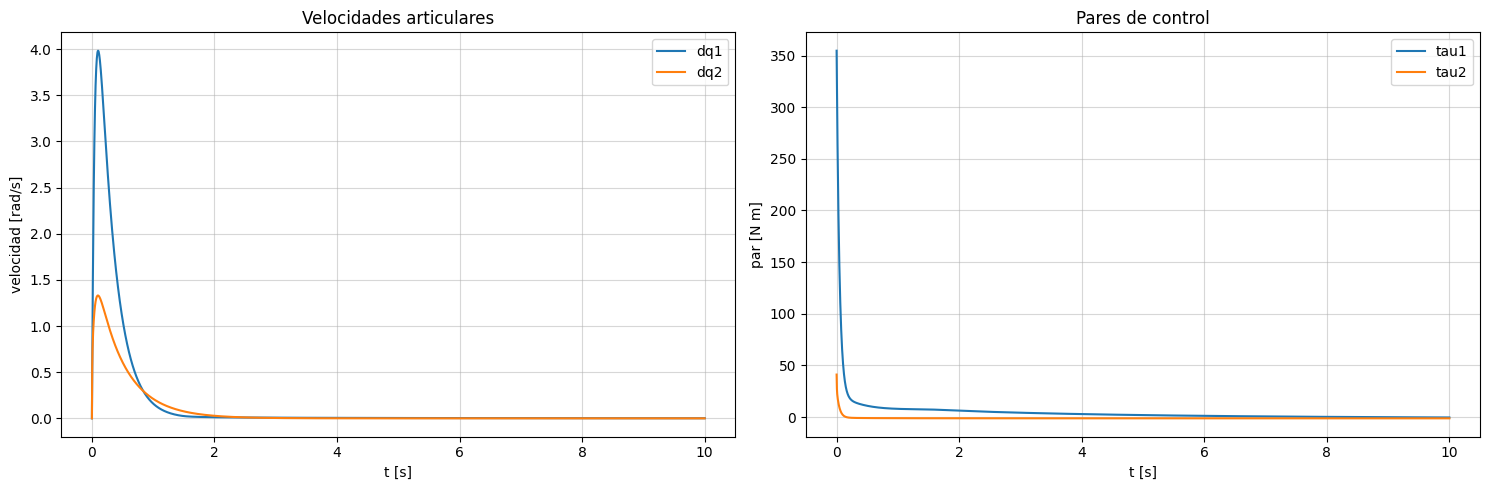

In [ ]:
# 5. Resultados numericos y graficas
# ---------------------------------------------------------------------------
sample_times = np.array([1.0, 2.0, 5.0, 10.0])
q1_samples = np.interp(sample_times, t, q1)
q2_samples = np.interp(sample_times, t, q2)

print("Resultados de la simulacion")
print(" t [s] | q1 [rad] | q2 [rad] | q1 [deg] | q2 [deg]")
print("-" * 58)
for ti, a1, a2 in zip(sample_times, q1_samples, q2_samples):
    print(
        f"{ti:6.1f} | {a1:8.4f} | {a2:8.4f} |"
        f" {np.rad2deg(a1):8.3f} | {np.rad2deg(a2):8.3f}"
    )

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

axes[0].plot(t, np.rad2deg(q1), label="q1", linewidth=2)
axes[0].plot(t, np.rad2deg(q2), label="q2", linewidth=2)
axes[0].axhline(90.0, color="C0", linestyle="--", alpha=0.35)
axes[0].axhline(45.0, color="C1", linestyle="--", alpha=0.35)
axes[0].set_xlabel("t [s]")
axes[0].set_ylabel("posicion [grados]")
axes[0].set_title("Respuesta angular")
axes[0].grid(True, alpha=0.5)
axes[0].legend()

axes[1].plot(x_ee, y_ee, linewidth=2)
axes[1].scatter(x_ee[0], y_ee[0], color="green", label="inicio", zorder=3)
axes[1].scatter(x_ee[-1], y_ee[-1], color="red", label="fin", zorder=3)
axes[1].set_xlabel("x [m]")
axes[1].set_ylabel("y [m]")
axes[1].set_title("Trayectoria del efector final")
axes[1].axis("equal")
axes[1].grid(True, alpha=0.5)
axes[1].legend()

plt.tight_layout()
plt.show()


# Graficas adicionales de velocidad y par de control
tau_history = np.column_stack(
    [control_torque(solution.y[:2, i], solution.y[2:, i]) for i in range(t.size)]
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(t, dq1, label="dq1")
axes[0].plot(t, dq2, label="dq2")
axes[0].set_xlabel("t [s]")
axes[0].set_ylabel("velocidad [rad/s]")
axes[0].set_title("Velocidades articulares")
axes[0].grid(True, alpha=0.5)
axes[0].legend()

axes[1].plot(t, tau_history[0], label="tau1")
axes[1].plot(t, tau_history[1], label="tau2")
axes[1].set_xlabel("t [s]")
axes[1].set_ylabel("par [N m]")
axes[1].set_title("Pares de control")
axes[1].grid(True, alpha=0.5)
axes[1].legend()

plt.tight_layout()
plt.show()
